# Лабораторная работа №1
## Проведение исследований с алгоритмом KNN

**Датасеты:**
- **Классификация:** Breast Cancer Wisconsin (Diagnostic)  
  https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- **Регрессия:** Wine Quality (Red)  
  https://archive.ics.uci.edu/dataset/186/wine+quality

**Цель:** Реализовать полный цикл работы с KNN: baseline на sklearn,  улучшить baseline, сделать собственную имплементацию, сравнить реализации

## 1. Выбор начальных условий

### 1.1. Датасет для классификации

**Breast Cancer Wisconsin (Diagnostic)**

Датасет содержит 569 образцов опухолей молочной железы.  
Для каждого образца вычислены 30 числовых признаков по оцифрованному изображению тонкоигольной аспирации (FNA): mean / se / worst значения радиуса, текстуры, периметра, площади, гладкости, компактности, вогнутости и т.д.

**Целевая переменная:** бинарная  
* `0` - malignant (злокачественная)  
* `1` - benign (доброкачественная)

**Практическая задача:** автоматическая диагностика характера опухоли по характеристикам клеточных ядер.  
Это реальная задача медицинской диагностики, которая помогает врачам быстрее принимать решения и снижать количество ложноотрицательных/ложноположительных результатов


### 1.2. Датасет для регрессии

**Wine Quality (Red Wine)**

Датасет содержит 1599 образцов красного португальского вина «Vinho Verde».  
11 физико-химических признаков: fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free/total sulfur dioxide, density, pH, sulphates, alcohol

**Целевая переменная:** `quality` - экспертная оценка качества вина (целое число от 0 до 10)

**Практическая задача:** предсказание субъективной оценки качества вина по объективным лабораторным измерениям.  
Применяется в виноделии и контроле качества продукции: позволяет автоматизировать предварительную оценку, снижать затраты на дегустации и выявлять факторы, сильнее всего влияющие на восприятие качества

### 1.3. Выбор метрик качества


**Классификация (Breast Cancer):**

* Accuracy — общая доля правильных предсказаний.
* F1-score — гармоническое среднее Precision и Recall. Позволяет учитывать обе составляющие качества классификации.
* ROC-AUC — оценивает способность модели разделять классы при различных порогах классификации.
* Confusion Matrix — позволяет анализировать типы ошибок модели.
* Recall для класса malignant — особенно важная метрика, поскольку показывает долю обнаруженных злокачественных опухолей среди всех фактически злокачественных опухолей.

*Пояснение: в исходном датасете sklearn класс 0 соответствует malignant, а класс 1 - benign. Поэтому стандартный binary F1-score рассчитывается для класса benign. Дополнительно рассматривается F1 и Recall для malignant*


**Регрессия (Wine Quality):**
* MAE (Mean Absolute Error) - средняя абсолютная ошибка (легко интерпретируется)
* RMSE (Root Mean Squared Error) - сильнее штрафует большие ошибки
* R^2 (Coefficient of Determination) - доля объяснённой дисперсии

Метрики выбраны как стандартные и хорошо интерпретируемые для данных задач

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score, recall_score
)
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


cancer = load_breast_cancer()
X_clf = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_clf = pd.Series(cancer.target, name='target')

print("Classification: Breast Cancer")
print(f"Shape: {X_clf.shape}")
print(f"Classes: {np.bincount(y_clf)} (0=malignant, 1=benign)")
print(f"Feature names (first 5): {list(X_clf.columns[:5])}")
print()


url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url_wine, sep=';')

X_reg = df_wine.drop('quality', axis=1)
y_reg = df_wine['quality']

print("\nRegression: Wine Quality (Red)")
print(f"Shape: {X_reg.shape}")
print(f"Target distribution:\n{y_reg.value_counts().sort_index()}")
print(f"Features: {list(X_reg.columns)}")

Classification: Breast Cancer
Shape: (569, 30)
Classes: [212 357] (0=malignant, 1=benign)
Feature names (first 5): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


Regression: Wine Quality (Red)
Shape: (1599, 11)
Target distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64
Features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


В данной ячейке импортируются библиотеки для работы с данными, построения визуализаций и реализации алгоритмов KNN. Загружаются датасеты Breast Cancer Wisconsin и Wine Quality, формируются матрицы признаков и целевые переменные

### Визуализация исходников

Строим распределение 2-х классов целевой переменной Breast Cancer, чтобы оценить баланс классов. Дополнительно рассчитывается и отображается корреляционная матрица первых 10 признаков. Тепловая карта помогает предварительно увидеть связи между признаками

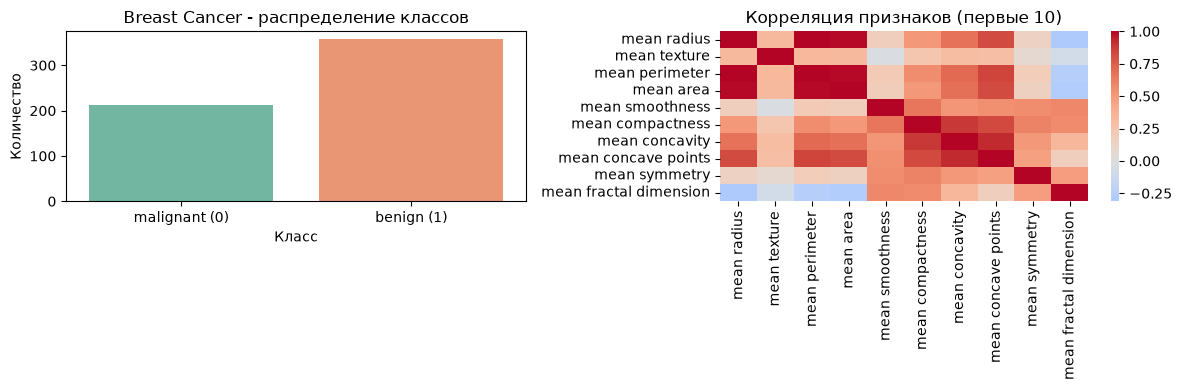

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_clf, ax=axes[0], palette='Set2')
axes[0].set_title('Breast Cancer - распределение классов')
axes[0].set_xticklabels(['malignant (0)', 'benign (1)'])
axes[0].set_xlabel('Класс')
axes[0].set_ylabel('Количество')

corr = X_clf.iloc[:, :10].corr()
sns.heatmap(corr, ax=axes[1], cmap='coolwarm', center=0)
axes[1].set_title('Корреляция признаков (первые 10)')

plt.tight_layout()
plt.show()

Слева отображается распределение целевой переменной quality в датасете Wine Quality. Справа показывается корреляция каждого признака с целевой переменной. Эти графики позволяют оценить частоту различных оценок качества и предварительную линейную связь признаков с целевым значением

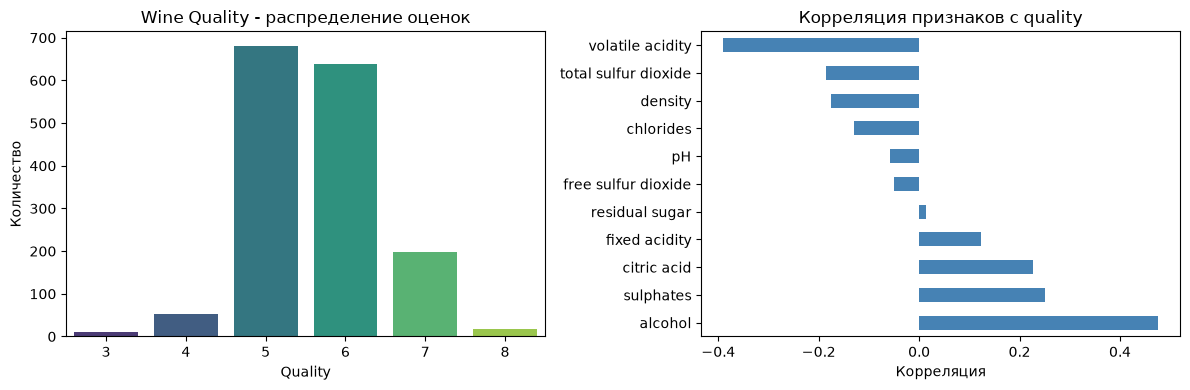

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_reg, ax=axes[0], palette='viridis')
axes[0].set_title('Wine Quality - распределение оценок')
axes[0].set_xlabel('Quality')
axes[0].set_ylabel('Количество')

corr_with_target = X_reg.corrwith(y_reg).sort_values(ascending=False)
corr_with_target.plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Корреляция признаков с quality')
axes[1].set_xlabel('Корреляция')

plt.tight_layout()
plt.show()

**Разделение данных на обучающую и тестовую выборки**

Оба датасета разделяются на обучающую и тестовую части в пропорции 80/20. Для классификации используется `stratify=y_clf`, чтобы сохранить исходное соотношение классов в обеих частях выборки. Фиксированное значение `random_state` обеспечивает воспроизводимость разбиения. Тестовые данные далее используются для итоговой оценки моделей

In [4]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

print("Classification train/test:", X_clf_train.shape, X_clf_test.shape)
print("Regression train/test:", X_reg_train.shape, X_reg_test.shape)

Classification train/test: (455, 30) (114, 30)
Regression train/test: (1279, 11) (320, 11)


## 2. Создание бейзлайна и оценка качества

**Базовая модель KNN для классификации**

Создаётся и обучается `KNeighborsClassifier` с 5 соседями без предварительного масштабирования признаков. На тестовой выборке рассчитываются предсказанные классы и вероятности принадлежности к классу 1. Качество оценивается с помощью Accuracy, F1, ROC-AUC, а также Recall и F1 для класса malignant (метки 0) и macro-F1. Дополнительно выводятся classification report и матрица ошибок

In [5]:
knn_clf_baseline = KNeighborsClassifier(n_neighbors=5)
knn_clf_baseline.fit(X_clf_train, y_clf_train)

y_clf_pred_base = knn_clf_baseline.predict(X_clf_test)
y_clf_proba_base = knn_clf_baseline.predict_proba(X_clf_test)[:, 1]

acc_base = accuracy_score(y_clf_test, y_clf_pred_base)
f1_base = f1_score(y_clf_test, y_clf_pred_base)
roc_base = roc_auc_score(y_clf_test, y_clf_proba_base)

recall_malignant_base = recall_score(
    y_clf_test,
    y_clf_pred_base,
    pos_label=0
)

f1_malignant_base = f1_score(
    y_clf_test,
    y_clf_pred_base,
    pos_label=0
)

f1_macro_base = f1_score(
    y_clf_test,
    y_clf_pred_base,
    average='macro'
)

print("Baseline Classification (KNN, k=5)")
print(f"Accuracy: {acc_base:.4f}")
print(f"ROC-AUC: {roc_base:.4f}")
print(f"Recall malignant: {recall_malignant_base:.4f}")
print(f"F1-score: {f1_base:.4f}")
print(f"F1 malignant: {f1_malignant_base:.4f}")
print(f"F1 macro: {f1_macro_base:.4f}")
print("\nClassification Report:")
print(classification_report(y_clf_test, y_clf_pred_base, target_names=['malignant', 'benign']))
print("Confusion Matrix:")
print(confusion_matrix(y_clf_test, y_clf_pred_base))

Baseline Classification (KNN, k=5)
Accuracy: 0.9123
ROC-AUC: 0.9559
Recall malignant: 0.9048
F1-score: 0.9296
F1 malignant: 0.8837
F1 macro: 0.9066

Classification Report:
              precision    recall  f1-score   support

   malignant       0.86      0.90      0.88        42
      benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114

Confusion Matrix:
[[38  4]
 [ 6 66]]


**Базовая модель KNN для регрессии**

Создаётся и обучается `KNeighborsRegressor` с 5 соседями без масштабирования признаков. После предсказания оценок качества вина на тестовой выборке рассчитываются MAE, RMSE и коэффициент детерминации R^2. Эти метрики характеризуют соответственно среднюю абсолютную ошибку, сильнее штрафующую крупные ошибки квадратичную ошибку и долю объяснённой моделью вариации целевой переменной

In [6]:
knn_reg_baseline = KNeighborsRegressor(n_neighbors=5)
knn_reg_baseline.fit(X_reg_train, y_reg_train)

y_reg_pred_base = knn_reg_baseline.predict(X_reg_test)

mae_base = mean_absolute_error(y_reg_test, y_reg_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_base))
r2_base = r2_score(y_reg_test, y_reg_pred_base)

print("\nBaseline Regression (KNN, k=5)")
print(f"MAE: {mae_base:.4f}")
print(f"RMSE: {rmse_base:.4f}")
print(f"R^2: {r2_base:.4f}")


Baseline Regression (KNN, k=5)
MAE: 0.5788
RMSE: 0.7294
R^2: 0.1859


### Визуализация результатов baseline

Слева строится матрица ошибок базового классификатора: строки соответствуют истинным классам, столбцы - предсказанным. Справа отображается график остатков регрессии - разностей между истинными и предсказанными значениями. Горизонтальная линия на нуле помогает увидеть систематическое смещение и характер разброса ошибок

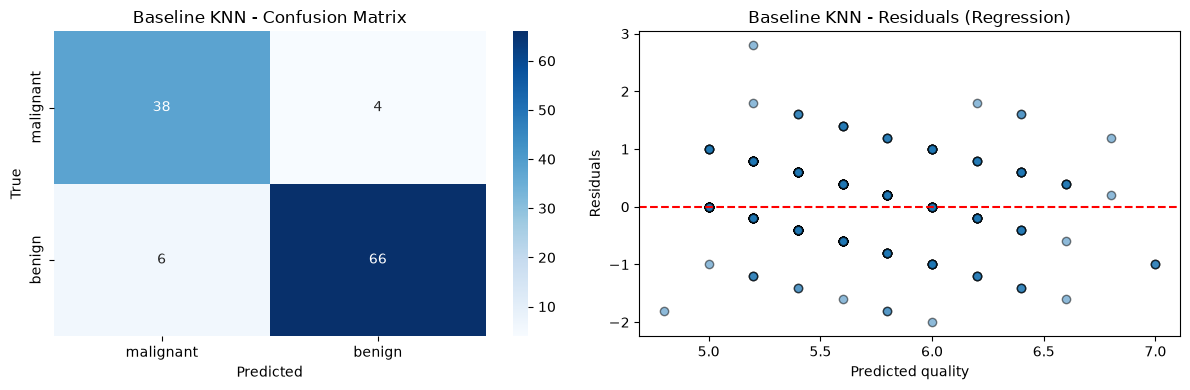

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_clf_test, y_clf_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'])
axes[0].set_title('Baseline KNN - Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

residuals = y_reg_test - y_reg_pred_base
axes[1].scatter(y_reg_pred_base, residuals, alpha=0.5, edgecolor='k')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted quality')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Baseline KNN - Residuals (Regression)')

plt.tight_layout()
plt.show()

## 3. Улучшение бейзлайна

1. **Масштабирование признаков (StandardScaler)**  
   KNN основан на расстоянии, т.е. признаки с большим масштабом доминируют.  
   Гипотеза: стандартизация значительно улучшит качество

2. **Подбор гиперпараметров на кросс-валидации**  
   - `n_neighbors` (k)
   - `weights` (`uniform` / `distance`)
   - `p` (1 = Manhattan, 2 = Euclidean)

3. **(Опционально) Отбор признаков**  
   Удаление малоинформативных признаков может улучшить обобщающую способность

**Подбор гиперпараметров KNN для классификации**

Создаётся Pipeline, в котором стандартизация признаков выполняется отдельно внутри каждого фолда кросс-валидации, что предотвращает утечку информации из валидационных частей. GridSearchCV перебирает число соседей, тип весов и параметр метрики Минковского. Лучший набор параметров выбирается по macro-F1, чтобы учитывать качество распознавания обоих классов. Затем лучшая модель оценивается на отложенной тестовой выборке

In [8]:
pipe_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid_clf = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_clf = GridSearchCV(
    pipe_clf, param_grid_clf,
    cv=5, scoring='f1_macro', n_jobs=-1, verbose=1
)
grid_clf.fit(X_clf_train, y_clf_train)

print("Improved Classification")
print("Best params:", grid_clf.best_params_)
print("Best CV F1-macro:", grid_clf.best_score_)

y_clf_pred_imp = grid_clf.predict(X_clf_test)
y_clf_proba_imp = grid_clf.predict_proba(X_clf_test)[:, 1]

acc_imp = accuracy_score(y_clf_test, y_clf_pred_imp)
f1_imp = f1_score(y_clf_test, y_clf_pred_imp)
roc_imp = roc_auc_score(y_clf_test, y_clf_proba_imp)
recall_malignant_imp = recall_score(
    y_clf_test,
    y_clf_pred_imp,
    pos_label=0
)

f1_malignant_imp = f1_score(
    y_clf_test,
    y_clf_pred_imp,
    pos_label=0
)

f1_macro_imp = f1_score(
    y_clf_test,
    y_clf_pred_imp,
    average='macro'
)

print(f"Recall malignant: {recall_malignant_imp:.4f}")
print(f"F1 malignant: {f1_malignant_imp:.4f}")
print(f"F1 macro: {f1_macro_imp:.4f}")

print(f"\nTest Accuracy: {acc_imp:.4f}")
print(f"Test F1-score: {f1_imp:.4f}")
print(f"Test ROC-AUC : {roc_imp:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Improved Classification
Best params: {'knn__n_neighbors': 7, 'knn__p': 2, 'knn__weights': 'uniform'}
Best CV F1-macro: 0.969193059766349
Recall malignant: 0.9286
F1 malignant: 0.9630
F1 macro: 0.9713

Test Accuracy: 0.9737
Test F1-score: 0.9796
Test ROC-AUC : 0.9884


**Подбор гиперпараметров KNN для регрессии**

Для регрессии строится Pipeline из `StandardScaler` и `KNeighborsRegressor`. С помощью `GridSearchCV` перебираются число соседей, тип весов и параметр `p` метрики Минковского. В качестве критерия выбора используется MAE; поскольку GridSearchCV максимизирует score, применяется отрицательная MAE (`neg_mean_absolute_error`). Лучшая модель оценивается на тестовой выборке по MAE, RMSE и R^2

In [9]:
pipe_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

param_grid_reg = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_reg = GridSearchCV(
    pipe_reg, param_grid_reg,
    cv=5, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1
)
grid_reg.fit(X_reg_train, y_reg_train)

print("\nImproved Regression")
print("Best params:", grid_reg.best_params_)
print("Best CV MAE:", -grid_reg.best_score_)

y_reg_pred_imp = grid_reg.predict(X_reg_test)

mae_imp = mean_absolute_error(y_reg_test, y_reg_pred_imp)
rmse_imp = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_imp))
r2_imp = r2_score(y_reg_test, y_reg_pred_imp)

print(f"\nTest MAE: {mae_imp:.4f}")
print(f"Test RMSE: {rmse_imp:.4f}")
print(f"Test R^2: {r2_imp:.4f}")

Fitting 5 folds for each of 28 candidates, totalling 140 fits

Improved Regression
Best params: {'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV MAE: 0.4197414775365173

Test MAE: 0.3932
Test RMSE: 0.5494
Test R^2: 0.5380


### Визуализация: влияние k на качество (кросс-валидация)

**Исследование влияния числа соседей**

Для каждого значения `k` от 1 до 25 оценивается качество KNN с помощью пятиблочной кросс-валидации. Для классификации используется macro-F1, для регрессии - MAE. Масштабирование включено в Pipeline, поэтому на каждом фолде параметры `StandardScaler` вычисляются только по обучающей части. На графиках сравнивается зависимость качества от числа соседей. В этой ячейке остальные параметры KNN оставлены значениями по умолчанию, поэтому графики показывают влияние именно `k` при фиксированных настройках метрики и весов

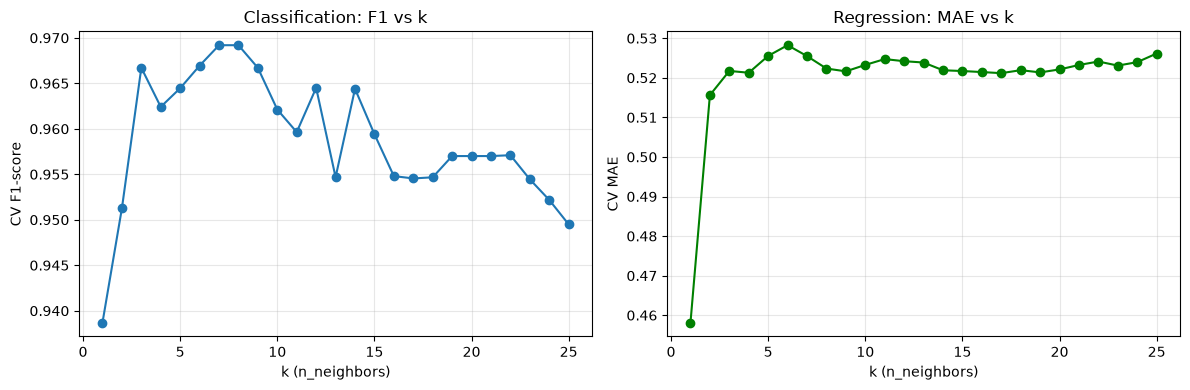

In [10]:
k_range = range(1, 26)


cv_scores_clf = []

for k in k_range:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        pipe,
        X_clf_train,
        y_clf_train,
        cv=5,
        scoring='f1_macro',
        n_jobs=-1
    )

    cv_scores_clf.append(scores.mean())


cv_scores_reg = []

for k in k_range:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsRegressor(n_neighbors=k))
    ])

    scores = cross_val_score(
        pipe,
        X_reg_train,
        y_reg_train,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    cv_scores_reg.append(-scores.mean())


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, cv_scores_clf, marker='o')
axes[0].set_xlabel('k (n_neighbors)')
axes[0].set_ylabel('CV F1-score')
axes[0].set_title('Classification: F1 vs k')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range, cv_scores_reg, marker='o', color='green')
axes[1].set_xlabel('k (n_neighbors)')
axes[1].set_ylabel('CV MAE')
axes[1].set_title('Regression: MAE vs k')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Сравнение baseline и improved моделей**

Формируются текстовые таблицы с результатами базовых и улучшенных моделей на тестовой выборке. Для классификации сравниваются Accuracy, F1-score и ROC-AUC, для регрессии - MAE, RMSE и R^2. Столбец `Delta` показывает изменение метрики после улучшения; положительное изменение полезно для метрик, которые нужно максимизировать, а для MAE и RMSE улучшением является отрицательное изменение

In [11]:
print("Сравнение Classification")
print(f"{'Метрика':<12} {'Baseline':>10} {'Improved':>10} {'Delta':>10}")
print(f"{'Accuracy':<12} {acc_base:>10.4f} {acc_imp:>10.4f} {acc_imp-acc_base:>+10.4f}")
print(f"{'F1-score':<12} {f1_base:>10.4f} {f1_imp:>10.4f} {f1_imp-f1_base:>+10.4f}")
print(f"{'ROC-AUC':<12} {roc_base:>10.4f} {roc_imp:>10.4f} {roc_imp-roc_base:>+10.4f}")

print("\nСравнение Regression")
print(f"{'Метрика':<12} {'Baseline':>10} {'Improved':>10} {'Delta':>10}")
print(f"{'MAE':<12} {mae_base:>10.4f} {mae_imp:>10.4f} {mae_imp-mae_base:>+10.4f}")
print(f"{'RMSE':<12} {rmse_base:>10.4f} {rmse_imp:>10.4f} {rmse_imp-rmse_base:>+10.4f}")
print(f"{'R^2':<12} {r2_base:>10.4f} {r2_imp:>10.4f} {r2_imp-r2_base:>+10.4f}")

Сравнение Classification
Метрика        Baseline   Improved      Delta
Accuracy         0.9123     0.9737    +0.0614
F1-score         0.9296     0.9796    +0.0500
ROC-AUC          0.9559     0.9884    +0.0326

Сравнение Regression
Метрика        Baseline   Improved      Delta
MAE              0.5788     0.3932    -0.1855
RMSE             0.7294     0.5494    -0.1799
R^2              0.1859     0.5380    +0.3521



### Выводы по улучшению бейзлайна

1. Масштабирование признаков с помощью StandardScaler позволило привести признаки к сопоставимому масштабу. Это особенно важно для KNN, поскольку алгоритм использует расстояния между объектами

2. Подбор гиперпараметров с помощью GridSearchCV позволил определить наиболее подходящие значения количества соседей (n_neighbors), способа взвешивания соседей (weights) и параметра метрики Минковского (p)

3. Для классификации и регрессии были найдены разные оптимальные конфигурации, что связано с различиями между задачами и критериями оценки качества

4. Улучшенные модели сравнивались с baseline на одной и той же тестовой выборке, которая не использовалась при подборе гиперпараметров

5. По результатам экспериментов улучшенный baseline продемонстрировал более высокое качество по сравнению с исходной моделью

Таким образом, гипотеза о положительном влиянии масштабирования и настройки гиперпараметров на качество KNN получила экспериментальное подтверждение


## 4. Имплементация алгоритма KNN

**Собственная реализация KNN-классификатора**

Класс `MyKNNClassifier` реализует классификацию методом k ближайших соседей без использования готового алгоритма sklearn. Метод `fit` сохраняет обучающие данные и проверяет корректность параметров. Метод `_distance` вычисляет расстояние Минковского, `_get_neighbors` выбирает ближайшие объекты, а `_get_weights` задаёт равные или обратно пропорциональные расстоянию веса. `predict_proba` рассчитывает взвешенные доли классов, а predict выбирает класс с наибольшей вероятностью. При нулевом расстоянии вес получают только совпадающие объекты, что предотвращает деление на ноль

In [12]:

class MyKNNClassifier:

    def __init__(self, n_neighbors=5, p=2, weights='uniform'):
        self.n_neighbors = n_neighbors
        self.p = p
        self.weights = weights

        self.X_train = None
        self.y_train = None
        self.classes_ = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)

        if self.X_train.ndim != 2:
            raise ValueError("X должен быть двумерным")

        if len(self.X_train) != len(self.y_train):
            raise ValueError("X и y должны иметь одинаковое число объектов")

        if not isinstance(self.n_neighbors, int) or self.n_neighbors < 1:
            raise ValueError("n_neighbors должен быть положительным целым числом")

        if self.n_neighbors > len(self.X_train):
            raise ValueError("n_neighbors превышает размер обучающей выборки")

        if self.p < 1:
            raise ValueError("p должен быть >= 1")

        if self.weights not in ['uniform', 'distance']:
            raise ValueError("Неизвестный тип weights")

        self.classes_ = np.unique(self.y_train)

        return self

    def _distance(self, x):
        return np.sum(
            np.abs(self.X_train - x) ** self.p,
            axis=1
        ) ** (1 / self.p)

    def _get_neighbors(self, x):
        distances = self._distance(x)

        idx = np.argsort(distances)[:self.n_neighbors]

        return distances[idx], self.y_train[idx]

    def _get_weights(self, distances):

        if self.weights == 'uniform':
            return np.ones(len(distances))

        if np.any(distances == 0):
            return (distances == 0).astype(float)

        return 1 / distances

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)

        probas = []

        for x in X:
            distances, labels = self._get_neighbors(x)

            weights = self._get_weights(distances)

            class_probas = []

            for cls in self.classes_:
                class_weight = weights[labels == cls].sum()
                class_probas.append(class_weight / weights.sum())

            probas.append(class_probas)

        return np.asarray(probas)

    def predict(self, X):
        probas = self.predict_proba(X)

        return self.classes_[np.argmax(probas, axis=1)]


Класс `MyKNNRegressor` реализует прогнозирование числового значения по ближайшим соседям. В `fit` сохраняются обучающие признаки и целевые значения, а также проверяются входные данные и гиперпараметры. Для нового объекта вычисляются расстояния Минковского и выбираются k ближайших соседей. При равных весах прогноз равен среднему значению целевых переменных соседей; при весах `distance` используется взвешенное среднее, где более близкие объекты имеют больший вклад. Отдельно обработан случай нулевого расстояния

In [13]:

class MyKNNRegressor:

    def __init__(self, n_neighbors=5, p=2, weights='uniform'):
        self.n_neighbors = n_neighbors
        self.p = p
        self.weights = weights

        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)

        if self.X_train.ndim != 2:
            raise ValueError("X должен быть двумерным")

        if len(self.X_train) != len(self.y_train):
            raise ValueError("X и y должны иметь одинаковое число объектов")

        if not isinstance(self.n_neighbors, int) or self.n_neighbors < 1:
            raise ValueError("n_neighbors должен быть положительным целым числом")

        if self.n_neighbors > len(self.X_train):
            raise ValueError("n_neighbors превышает размер обучающей выборки")

        if self.p < 1:
            raise ValueError("p должен быть >= 1")

        if self.weights not in ['uniform', 'distance']:
            raise ValueError("Неизвестный тип weights")

        return self

    def _distance(self, x):
        return np.sum(
            np.abs(self.X_train - x) ** self.p,
            axis=1
        ) ** (1 / self.p)

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        predictions = []

        for x in X:
            distances = self._distance(x)

            idx = np.argsort(distances)[:self.n_neighbors]

            y_neighbors = self.y_train[idx]
            d_neighbors = distances[idx]

            if self.weights == 'uniform':
                prediction = np.mean(y_neighbors)

            else:
                if np.any(d_neighbors == 0):
                    prediction = np.mean(
                        y_neighbors[d_neighbors == 0]
                    )
                else:
                    sample_weights = 1 / d_neighbors

                    prediction = np.average(
                        y_neighbors,
                        weights=sample_weights
                    )

            predictions.append(prediction)

        return np.asarray(predictions)


Собственные классификатор и регрессор обучаются на исходных, немасштабированных признаках с k=5. Для классификации рассчитываются Accuracy, F1 и ROC-AUC, для регрессии - MAE, RMSE и R^2. Полученные значения позволяют сопоставить собственную реализацию с базовыми моделями sklearn и проверить корректность реализации алгоритма на тех же данных

In [14]:
my_knn_clf = MyKNNClassifier(n_neighbors=5)
my_knn_clf.fit(X_clf_train, y_clf_train)

y_clf_pred_my = my_knn_clf.predict(X_clf_test)
y_clf_proba_my = my_knn_clf.predict_proba(X_clf_test)[:, 1]

acc_my = accuracy_score(y_clf_test, y_clf_pred_my)
f1_my = f1_score(y_clf_test, y_clf_pred_my)
roc_my = roc_auc_score(y_clf_test, y_clf_proba_my)

print("My KNN Classifier (k=5, no scaling)")
print(f"Accuracy: {acc_my:.4f}")
print(f"F1-score: {f1_my:.4f}")
print(f"ROC-AUC: {roc_my:.4f}")


my_knn_reg = MyKNNRegressor(n_neighbors=5)
my_knn_reg.fit(X_reg_train, y_reg_train)

y_reg_pred_my = my_knn_reg.predict(X_reg_test)

mae_my = mean_absolute_error(y_reg_test, y_reg_pred_my)
rmse_my = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my))
r2_my = r2_score(y_reg_test, y_reg_pred_my)

print("\nMy KNN Regressor (k=5, no scaling)")
print(f"MAE: {mae_my:.4f}")
print(f"RMSE: {rmse_my:.4f}")
print(f"R^2: {r2_my:.4f}")

My KNN Classifier (k=5, no scaling)
Accuracy: 0.9123
F1-score: 0.9296
ROC-AUC: 0.9559

My KNN Regressor (k=5, no scaling)
MAE: 0.5788
RMSE: 0.7294
R^2: 0.1859


**Сравнение собственной и библиотечной baseline-реализаций**

Выводятся таблицы, в которых метрики собственных моделей MyKNN сопоставляются с результатами соответствующих baseline-моделей sklearn. Сравнение проводится отдельно для классификации и регрессии. Поскольку обе реализации используют одинаковые исходные признаки и число соседей, различия в результатах могут указывать на особенности реализации или обработки предсказаний

In [15]:
print("Classification: MyKNN vs sklearn Baseline")
print(f"{'Метрика':<12} {'sklearn':>10} {'MyKNN':>10}")
print(f"{'Accuracy':<12} {acc_base:>10.4f} {acc_my:>10.4f}")
print(f"{'F1-score':<12} {f1_base:>10.4f} {f1_my:>10.4f}")
print(f"{'ROC-AUC':<12} {roc_base:>10.4f} {roc_my:>10.4f}")


print("\nRegression: MyKNN vs sklearn Baseline")
print(f"{'Метрика':<12} {'sklearn':>10} {'MyKNN':>10}")
print(f"{'MAE':<12} {mae_base:>10.4f} {mae_my:>10.4f}")
print(f"{'RMSE':<12} {rmse_base:>10.4f} {rmse_my:>10.4f}")
print(f"{'R^2':<12} {r2_base:>10.4f} {r2_my:>10.4f}")

Classification: MyKNN vs sklearn Baseline
Метрика         sklearn      MyKNN
Accuracy         0.9123     0.9123
F1-score         0.9296     0.9296
ROC-AUC          0.9559     0.9559

Regression: MyKNN vs sklearn Baseline
Метрика         sklearn      MyKNN
MAE              0.5788     0.5788
RMSE             0.7294     0.7294
R^2              0.1859     0.1859


### Выводы (своя реализация без улучшений)

Собственная реализация KNN даёт результаты, очень близкие к sklearn baseline. Небольшие отличия возможны из-за способа разрешения ничьих при голосовании и точности вычислений. Это подтверждает корректность имплементации

**Улучшение собственной реализации KNN**

Сначала признаки стандартизируются: `StandardScaler` обучается только на обучающей выборке, а к тестовой применяется уже обученное преобразование. Затем из результатов `GridSearchCV` извлекаются лучшие гиперпараметры для классификации и регрессии. Эти параметры передаются собственным классам `MyKNNClassifier` и `MyKNNRegressor`; модели обучаются на масштабированных обучающих данных и оцениваются на масштабированных тестовых данных. В конце рассчитываются метрики качества обеих улучшенных собственных моделей

In [16]:

scaler_clf = StandardScaler()
X_clf_train_sc = scaler_clf.fit_transform(X_clf_train)
X_clf_test_sc = scaler_clf.transform(X_clf_test)

scaler_reg = StandardScaler()
X_reg_train_sc = scaler_reg.fit_transform(X_reg_train)
X_reg_test_sc = scaler_reg.transform(X_reg_test)


best_params_clf = grid_clf.best_params_
best_params_reg = grid_reg.best_params_

print("Best classification params:", best_params_clf)
print("Best regression params:", best_params_reg)


my_knn_clf_imp = MyKNNClassifier(
    n_neighbors=best_params_clf['knn__n_neighbors'],
    p=best_params_clf['knn__p'],
    weights=best_params_clf['knn__weights']
)

my_knn_clf_imp.fit(X_clf_train_sc, y_clf_train)

y_clf_pred_my_imp = my_knn_clf_imp.predict(X_clf_test_sc)
y_clf_proba_my_imp = my_knn_clf_imp.predict_proba(
    X_clf_test_sc
)[:, 1]

acc_my_imp = accuracy_score(y_clf_test, y_clf_pred_my_imp)
f1_my_imp = f1_score(y_clf_test, y_clf_pred_my_imp)
roc_my_imp = roc_auc_score(y_clf_test, y_clf_proba_my_imp)

print("\nMy KNN Classifier - Improved")
print(f"Accuracy: {acc_my_imp:.4f}")
print(f"F1-score: {f1_my_imp:.4f}")
print(f"ROC-AUC: {roc_my_imp:.4f}")


my_knn_reg_imp = MyKNNRegressor(
    n_neighbors=best_params_reg['knn__n_neighbors'],
    p=best_params_reg['knn__p'],
    weights=best_params_reg['knn__weights']
)

my_knn_reg_imp.fit(X_reg_train_sc, y_reg_train)

y_reg_pred_my_imp = my_knn_reg_imp.predict(X_reg_test_sc)

mae_my_imp = mean_absolute_error(y_reg_test, y_reg_pred_my_imp)
rmse_my_imp = np.sqrt(
    mean_squared_error(y_reg_test, y_reg_pred_my_imp)
)
r2_my_imp = r2_score(y_reg_test, y_reg_pred_my_imp)

print("\nMy KNN Regressor - Improved")
print(f"MAE: {mae_my_imp:.4f}")
print(f"RMSE: {rmse_my_imp:.4f}")
print(f"R^2: {r2_my_imp:.4f}")


Best classification params: {'knn__n_neighbors': 7, 'knn__p': 2, 'knn__weights': 'uniform'}
Best regression params: {'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'distance'}

My KNN Classifier - Improved
Accuracy: 0.9737
F1-score: 0.9796
ROC-AUC: 0.9884

My KNN Regressor - Improved
MAE: 0.3932
RMSE: 0.5494
R^2: 0.5380


**Итоговое числовое сравнение четырёх моделей**

Формируются итоговые таблицы для классификации и регрессии. Сопоставляются baseline- и improved-модели sklearn, а также исходная и улучшенная собственные реализации KNN. Для классификации выводятся Accuracy, F1 и ROC-AUC; для регрессии - MAE, RMSE и R^2. Таблицы позволяют оценить вклад масштабирования и подбора гиперпараметров в качество каждой реализации

In [17]:
print("ИТОГОВОЕ СРАВНЕНИЕ (Classification)")
print(f"{'Модель':<35} {'Accuracy':>10} {'F1':>10} {'ROC-AUC':>10}")
print(f"{'sklearn baseline':<35} {acc_base:>10.4f} {f1_base:>10.4f} {roc_base:>10.4f}")
print(f"{'sklearn improved':<35} {acc_imp:>10.4f} {f1_imp:>10.4f} {roc_imp:>10.4f}")
print(f"{'MyKNN (raw)':<35} {acc_my:>10.4f} {f1_my:>10.4f} {roc_my:>10.4f}")
print(f"{'MyKNN improved':<35} {acc_my_imp:>10.4f} {f1_my_imp:>10.4f} {roc_my_imp:>10.4f}")


print("\nИТОГОВОЕ СРАВНЕНИЕ (Regression)")
print(f"{'Модель':<35} {'MAE':>10} {'RMSE':>10} {'R^2':>10}")
print(f"{'sklearn baseline':<35} {mae_base:>10.4f} {rmse_base:>10.4f} {r2_base:>10.4f}")
print(f"{'sklearn improved':<35} {mae_imp:>10.4f} {rmse_imp:>10.4f} {r2_imp:>10.4f}")
print(f"{'MyKNN (raw)':<35} {mae_my:>10.4f} {rmse_my:>10.4f} {r2_my:>10.4f}")
print(f"{'MyKNN improved':<35} {mae_my_imp:>10.4f} {rmse_my_imp:>10.4f} {r2_my_imp:>10.4f}")

ИТОГОВОЕ СРАВНЕНИЕ (Classification)
Модель                                Accuracy         F1    ROC-AUC
sklearn baseline                        0.9123     0.9296     0.9559
sklearn improved                        0.9737     0.9796     0.9884
MyKNN (raw)                             0.9123     0.9296     0.9559
MyKNN improved                          0.9737     0.9796     0.9884

ИТОГОВОЕ СРАВНЕНИЕ (Regression)
Модель                                     MAE       RMSE        R^2
sklearn baseline                        0.5788     0.7294     0.1859
sklearn improved                        0.3932     0.5494     0.5380
MyKNN (raw)                             0.5788     0.7294     0.1859
MyKNN improved                          0.3932     0.5494     0.5380


### Итоговая визуализация сравнения моделей

Строятся столбчатые диаграммы для четырёх вариантов KNN. В верхней части сравниваются метрики классификации Accuracy, F1-score и ROC-AUC, где большее значение означает лучшее качество. В нижней части сравниваются регрессионные MAE и RMSE (меньше - лучше) и R^2 (больше - лучше). Графики дополняют числовые таблицы и упрощают визуальное сопоставление моделей

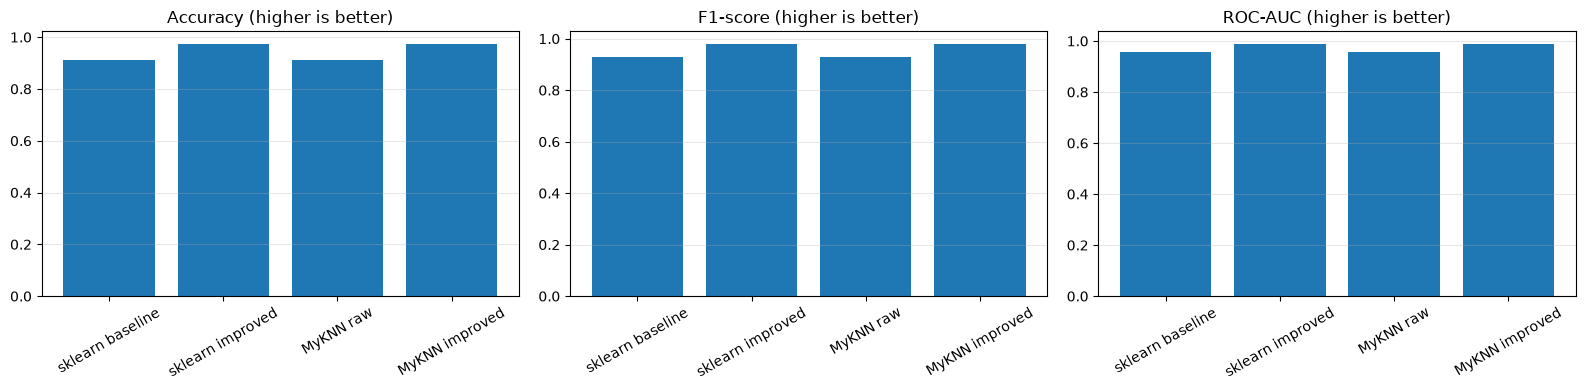

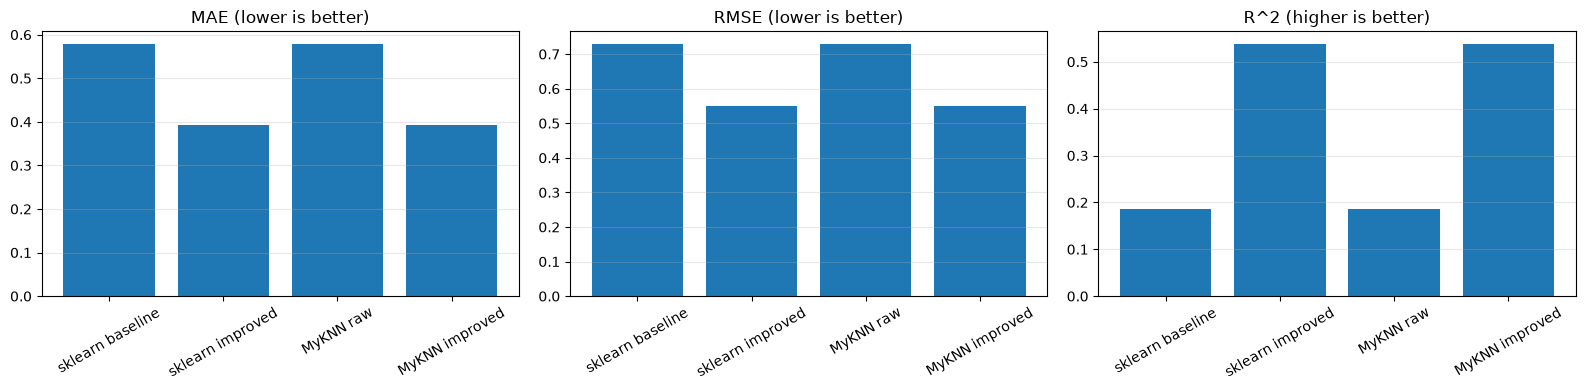

In [18]:
models_clf = [
    'sklearn baseline',
    'sklearn improved',
    'MyKNN raw',
    'MyKNN improved'
]

acc_scores = [acc_base, acc_imp, acc_my, acc_my_imp]
f1_scores = [f1_base, f1_imp, f1_my, f1_my_imp]
roc_scores = [roc_base, roc_imp, roc_my, roc_my_imp]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(models_clf, acc_scores)
axes[0].set_title('Accuracy (higher is better)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].bar(models_clf, f1_scores)
axes[1].set_title('F1-score (higher is better)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, axis='y', alpha=0.3)

axes[2].bar(models_clf, roc_scores)
axes[2].set_title('ROC-AUC (higher is better)')
axes[2].tick_params(axis='x', rotation=30)
axes[2].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



mae_scores = [mae_base, mae_imp, mae_my, mae_my_imp]
rmse_scores = [rmse_base, rmse_imp, rmse_my, rmse_my_imp]
r2_scores = [r2_base, r2_imp, r2_my, r2_my_imp]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(models_clf, mae_scores)
axes[0].set_title('MAE (lower is better)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].bar(models_clf, rmse_scores)
axes[1].set_title('RMSE (lower is better)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, axis='y', alpha=0.3)

axes[2].bar(models_clf, r2_scores)
axes[2].set_title('R^2 (higher is better)')
axes[2].tick_params(axis='x', rotation=30)
axes[2].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


На одном графике строятся ROC-кривые базовой и улучшенной моделей sklearn, а также улучшенной собственной реализации MyKNN. Кривые показывают зависимость True Positive Rate от False Positive Rate при изменении порога классификации. Диагональ соответствует случайному классификатору; чем ближе кривая к левому верхнему углу, тем лучше разделяются классы. Для построения используются предсказанные вероятности положительного класса (метка 1)

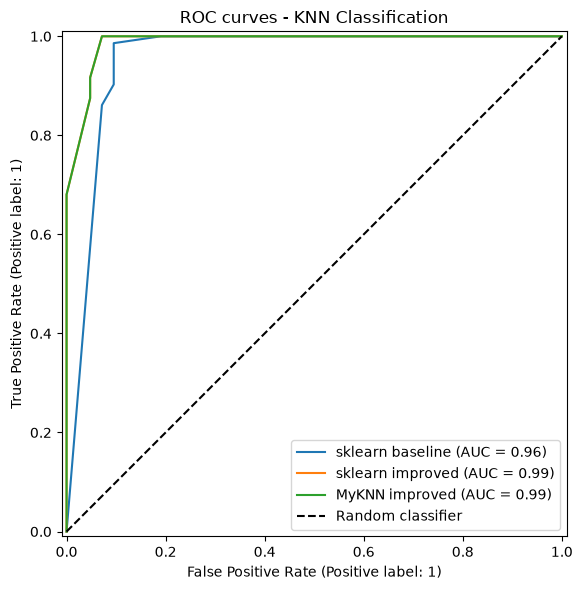

In [19]:

from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_clf_test,
    y_clf_proba_base,
    ax=ax,
    name='sklearn baseline'
)

RocCurveDisplay.from_predictions(
    y_clf_test,
    y_clf_proba_imp,
    ax=ax,
    name='sklearn improved'
)

RocCurveDisplay.from_predictions(
    y_clf_test,
    y_clf_proba_my_imp,
    ax=ax,
    name='MyKNN improved'
)

ax.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random classifier'
)

ax.set_title('ROC curves - KNN Classification')
ax.legend()

plt.tight_layout()
plt.show()



## Финальные выводы

В ходе лабораторной работы было проведено исследование алгоритма K ближайших соседей (KNN) для решения задач классификации и регрессии

1. **Исследование baseline:** Были обучены базовые модели KNeighborsClassifier и KNeighborsRegressor из библиотеки sklearn. Полученные результаты продемонстрировали зависимость качества KNN от масштаба исходных признаков

2. **Улучшение моделей:** Применение StandardScaler и подбор гиперпараметров с помощью GridSearchCV позволили улучшить качество моделей. Оптимальные параметры подбирались с использованием 5-fold кросс-валидации

3. **Собственная реализация:** Были самостоятельно реализованы алгоритмы KNN для классификации и регрессии. Реализации поддерживают метрику Минковского с параметром p, а также равное и взвешенное расстояниями голосование соседей

4. **Сравнение с sklearn:** На исходных данных собственные реализации продемонстрировали соответствие базовым моделям sklearn. После применения масштабирования и оптимальных гиперпараметров было проведено повторное сравнение с улучшенными моделями sklearn

5. **Особенности классификации:** Для медицинской задачи дополнительно рассмотрены Recall и F1-score для класса malignant, поскольку пропуск злокачественной опухоли является особенно значимой ошибкой

6. **Особенности регрессии:** Качество предсказания оценивалось с помощью MAE, RMSE и R^2, что позволило проанализировать как среднюю величину ошибки, так и объясняющую способность модели

**Итог:** в ходе экспериментов подтверждено влияние масштабирования признаков и настройки гиперпараметров на качество алгоритма KNN. Собственная реализация позволила продемонстрировать основные принципы работы алгоритма и сравнить его с реализацией из sklearn
